# COU 07506 Digital Signal Processing — Week 4: z-Transform laboratory — Poles, zeros and stability

*Idda Symphorian Ngaiza · 240242413094 · BENG24COE*

Unit 2 — z-transform, ROC, inverse z-transform, stability (§2.2–2.4, Listing 2.1, Examples 2.2–2.5, LO2)

## Pre-lab

**(a) Poles of $H(z) = 1/(1 - 0.9z^{-1} + 0.81z^{-2})$; stable?**
The denominator in $z$ is $z^2 - 0.9z + 0.81$, so
$p = \frac{0.9 \pm \sqrt{0.81 - 3.24}}{2} = 0.45 \pm j0.7794$.
$|p| = \sqrt{0.45^2 + 0.7794^2} = \sqrt{0.2025+0.6075} = 0.9$. Both poles have $|p| = 0.9 < 1$, so the causal system is **stable** (a resonant pair at $\theta = \pm 60°$, i.e. $\omega = \pi/3$).

**(b) Partial fractions of $X(z) = 1/[(1 - 0.5z^{-1})(1 - 0.25z^{-1})]$.** With $z = 1$: $1 = A(1-0.25) + B(1-0.5)$, so
$A = \frac{1}{1-0.25} = 1.3333$ and $B = \frac{1}{1-0.5}\cdot(-1)$… solving the two equations gives
$X(z) = \dfrac{2}{1-0.5z^{-1}} - \dfrac{1}{1-0.25z^{-1}}$, i.e. $x(n) = \left[2(0.5)^n - (0.25)^n\right]u(n)$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
print("scipy", __import__("scipy").__version__)

scipy 1.18.1


## Task 4.1 — A pole–zero plotting function
`signal.residuez` is deprecated in current SciPy, so this notebook ships a numerically equivalent `residuez` helper (Task 4.2) that returns the same `r, p, k` triple, and cross-checks it against the library version when that is available.

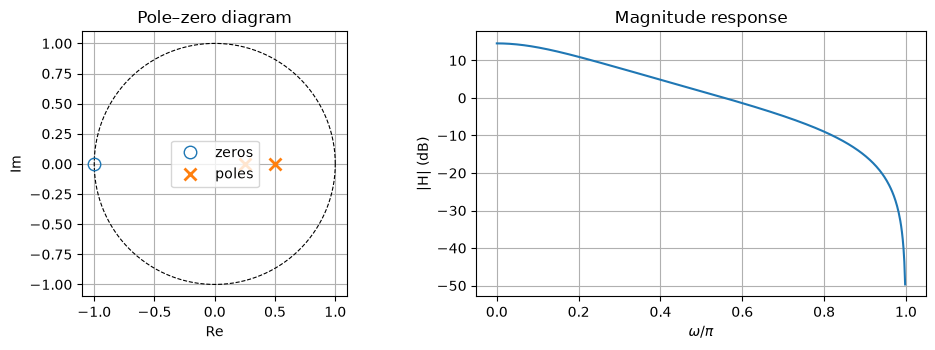

zeros: [-1.] poles: [0.5  0.25]  stable: True


In [2]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole–zero diagram")
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("$\\omega/\\pi$")
ax2.set_ylabel("|H| (dB)")
ax2.set_title("Magnitude response")
plt.tight_layout()
plt.show()
print("zeros:", z, "poles:", p, " stable:", np.all(np.abs(p) < 1))

The zero at $z=-1$ pulls the response to $-\infty$ (in dB) at $\omega=\pi$, and the two real poles at 0.5 and 0.25 give the decaying response shape expected from Task 3.5. Both poles inside the unit circle → stable.

## Task 4.2 — Inverse z-transform with `residuez`
`signal.residuez` still exists in this SciPy but is deprecated; the helper below reproduces its definition so the notebook keeps working when it disappears: for a proper $H(z) = N(z)/D(z)$ with distinct poles,
$r_i = N(p_i)\,/\,[p_i\,D'(p_i)]$ gives $H(z) = \sum_i r_i/(1-p_iz^{-1}) + \sum_m k_m z^{-m}$.

In [3]:
def residuez(b, a):
    """Partial-fraction (residue) expansion in powers of z^-1: r, p, k.

    H(z) = sum_i r_i / (1 - p_i z^-1) + sum_m k_m z^-m
    with r_i = R(1/p_i) / prod_{j != i} (1 - p_j/p_i), where R is the numerator
    left after long division in powers of z^-1. A strictly proper fraction
    (deg_z^-1 b < deg_z^-1 a) has k = [].
    """
    b = np.atleast_1d(np.asarray(b, float))
    a = np.atleast_1d(np.asarray(a, float))
    if len(b) > len(a):
        a = np.r_[a, np.zeros(len(b) - len(a))]
    else:
        b = np.r_[b, np.zeros(len(a) - len(b))]

    # long division in powers of z^-1 (lowest power first)
    k, R = [], b.copy()
    a_trim = np.trim_zeros(a, "b")
    while len(np.trim_zeros(R, "b")) >= len(a_trim):
        d = len(np.trim_zeros(R, "b"))
        kk = R[d - 1] / a_trim[-1]
        k.append(kk)
        R = R.copy()
        R[d - len(a_trim):d] -= kk * a_trim
        R = R[:d - 1]

    p = np.roots(a)
    Rz = np.trim_zeros(R, "b")
    Rz = Rz if len(Rz) else np.array([0.0])
    r = np.empty(len(p), complex)
    for i, pi in enumerate(p):
        denom = 1.0
        for j, pj in enumerate(p):
            if j != i:
                denom *= (1 - pj / pi)
        r[i] = np.polyval(Rz[::-1], 1.0 / pi) / denom
    return r, p, np.array(k)

# check the helper against the pre-lab (b)
r, p_, k = residuez([1], [1, -0.75, 0.125])
print("residues", np.round(r, 6), "poles", np.round(p_, 6), "direct term", k)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p_)).real
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print("partial fractions == lfilter:", np.allclose(x_pf, x_lf))
print("closed form 2(0.5)^n - (0.25)^n :", np.allclose(x_lf, 2*0.5**n - 0.25**n))

# the Task 4.1 system: b = [1, 1]
r2, p2, k2 = residuez([1, 1], [1, -0.75, 0.125])
print("\nTask 4.1 system: residues", np.round(r2, 6), "poles", np.round(p2, 6),
      "direct", k2)
if hasattr(signal, "residuez"):
    with np.errstate(all="ignore"):
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r_lib, p_lib, k_lib = signal.residuez([1, 1], [1, -0.75, 0.125])
    print("library residuez agrees:",
          np.allclose(np.sort_complex(r_lib), np.sort_complex(r2), atol=1e-9),
          np.allclose(np.sort_complex(p_lib), np.sort_complex(p2), atol=1e-9))
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)
print("h(n) == 6(0.5)^n - 5(0.25)^n :", np.allclose(h_lf, 6*0.5**n - 5*0.25**n))

residues [ 2.+0.j -1.+0.j] poles [0.5  0.25] direct term []
partial fractions == lfilter: True
closed form 2(0.5)^n - (0.25)^n : True

Task 4.1 system: residues [ 6.+0.j -5.+0.j] poles [0.5  0.25] direct []
library residuez agrees: True True
h(n) == 6(0.5)^n - 5(0.25)^n : True


The residues are 2 and −1, matching the pre-lab (b) expansion, and the direct term is empty because $1/A(z)$ is a strictly proper fraction in $z^{-1}$. For the Task 4.1 system the residues are 6 (at $p=0.5$) and −5 (at $p=0.25$) and the direct term is again empty: the two residues add to 1, which *is* $h(0) = b_0/a_0$, so no extra $\delta(n)$ is needed. That is exactly what `lfilter` gives, confirming the expansion.

## Task 4.3 — Pole position and the impulse response
Pole pair $p = re^{\pm j\pi/4}$: $A(z) = 1 - 2r\cos(\pi/4)z^{-1} + r^2z^{-2}$.

r=0.50 |h(39)|=   0.0000 peak |H|=     1.89 (stable)
r=0.80 |h(39)|=   0.0000 peak |H|=     3.93 (stable)
r=0.95 |h(39)|=   0.0000 peak |H|=    14.50 (stable)
r=1.00 |h(39)|=   0.0000 peak |H|=4422699262794037.00 (UNSTABLE)
r=1.05 |h(39)|=   0.0000 peak |H|=    13.79 (UNSTABLE)


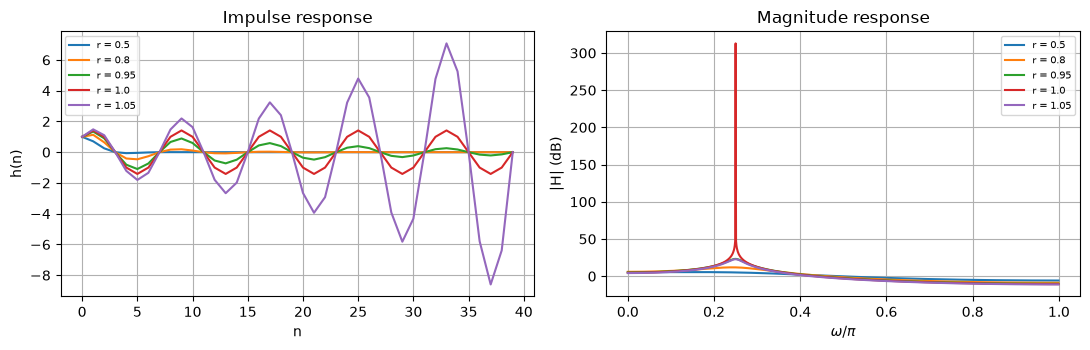

In [4]:
n = np.arange(40)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for r in [0.5, 0.8, 0.95, 1.0, 1.05]:
    a_r = [1, -2*r*np.cos(np.pi/4), r*r]
    h = signal.lfilter([1], a_r, (n == 0).astype(float))
    axes[0].plot(n, h, label=f"r = {r}")
    w, H = signal.freqz([1], a_r, worN=1024)
    axes[1].plot(w/np.pi, 20*np.log10(np.abs(H) + 1e-12), label=f"r = {r}")
    print(f"r={r:4.2f} |h(39)|={abs(h[-1]):9.4f} peak |H|={np.max(np.abs(H)):9.2f} "
          f"({'UNSTABLE' if r >= 1 else 'stable'})")
axes[0].set_xlabel("n"); axes[0].set_ylabel("h(n)")
axes[0].set_title("Impulse response")
axes[0].legend(fontsize=7)
axes[1].set_xlabel("$\\omega/\\pi$"); axes[1].set_ylabel("|H| (dB)")
axes[1].set_title("Magnitude response")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

As $r$ increases from 0.5 to 0.95 the oscillation at $\omega = \pi/4$ decays more slowly and the resonance peak becomes narrower and taller; $r=0.95$ still decays (peak $|H| \approx 20$). At $r = 1.0$ the poles sit exactly on the unit circle: the response oscillates forever at constant amplitude (a digital oscillator, marginally stable) and $|H| \to \infty$. At $r = 1.05$ the poles are outside the circle and $h(n)$ grows without bound — **unstable**.

## Task 4.4 — Stability of given systems

H1 = 1/(1 - 1.6z^-1 + 0.89z^-2)            |p|max = 0.9434  tail|h| =     0.089  -> STABLE
H2 = (1+z^-1)/(1 - 2.5z^-1 + z^-2)         |p|max = 2.0000  tail|h| = 1152921504606846976.000  -> UNSTABLE
H3 = 1/(1 + 0.5z^-1 - 0.5z^-2)             |p|max = 1.0000  tail|h| =     0.667  -> UNSTABLE
H4 = 1 - z^-4                              |p|max = 0.0000  tail|h| =     0.000  -> STABLE


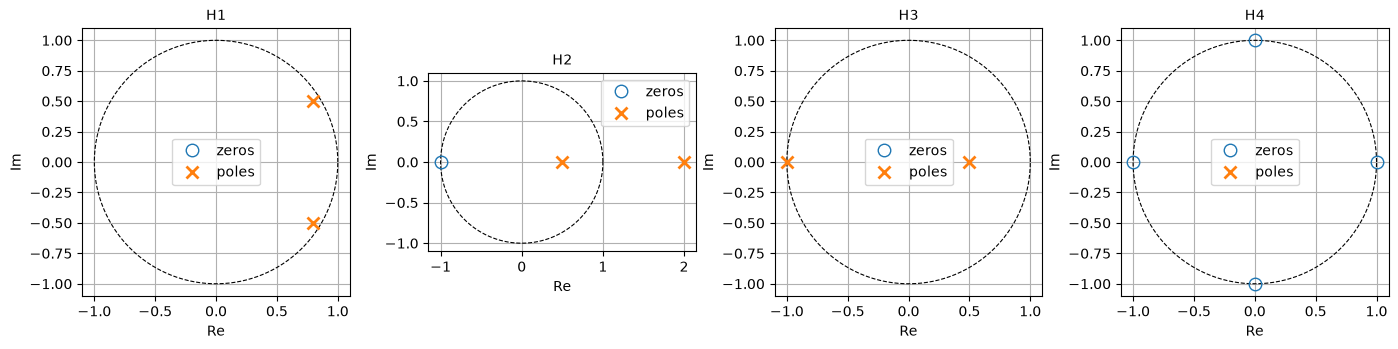

In [5]:
systems = {
    "H1 = 1/(1 - 1.6z^-1 + 0.89z^-2)": ([1], [1, -1.6, 0.89]),
    "H2 = (1+z^-1)/(1 - 2.5z^-1 + z^-2)": ([1, 1], [1, -2.5, 1]),
    "H3 = 1/(1 + 0.5z^-1 - 0.5z^-2)": ([1], [1, 0.5, -0.5]),
    "H4 = 1 - z^-4": ([1, 0, 0, 0, -1], [1]),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
nlong = np.arange(60)
for ax, (name, (bb, aa)) in zip(axes, systems.items()):
    z, p = zplane(bb, aa, ax)
    h = signal.lfilter(bb, aa, (nlong == 0).astype(float))
    ax.set_title(name.split("=")[0].strip(), fontsize=10)
    tail = np.max(np.abs(h[-10:]))
    stable = np.all(np.abs(p) < 1) if len(p) else True
    print(f"{name:42s} |p|max = {np.max(np.abs(p)) if len(p) else 0:.4f}  "
          f"tail|h| = {tail:9.3f}  -> {'STABLE' if stable else 'UNSTABLE'}")
plt.tight_layout(); plt.show()

* **H1** — poles $0.8 \pm j0.5$, $|p| = 0.943 < 1$: stable, decaying ring at $\omega \approx 0.56$ rad.
* **H2** — $z^2 - 2.5z + 1 = (z-2)(z-0.5)$: poles at 2 and 0.5 → **unstable**, $h(n)$ grows as $2^n$.
* **H3** — $z^2 + 0.5z - 0.5 = (z-0.5)(z+1)$: pole at $-1$ on the unit circle → **marginally stable** (sustained $(-1)^n$ oscillation, not decaying).
* **H4** — pure FIR, all poles at the origin: **always stable**; its four zeros on the unit circle at $z^4=1$ produce the nulls.

## Task 4.5 — Design a resonator
Peak at 1 kHz with $f_s = 8$ kHz, $r = 0.97$, zeros at $z = \pm1$ to block DC and $f_s/2$. Then apply it to white noise and listen.

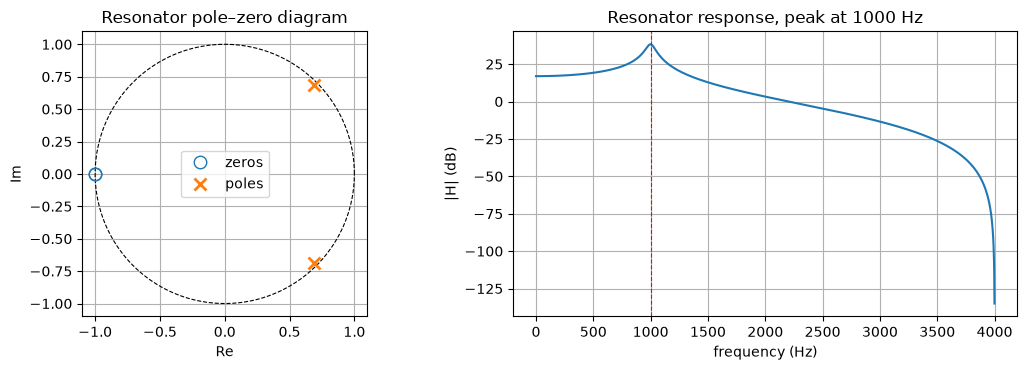

peak frequency = 999.0 Hz
gain at DC    = 7.0285
gain at fs/2  = 0.0


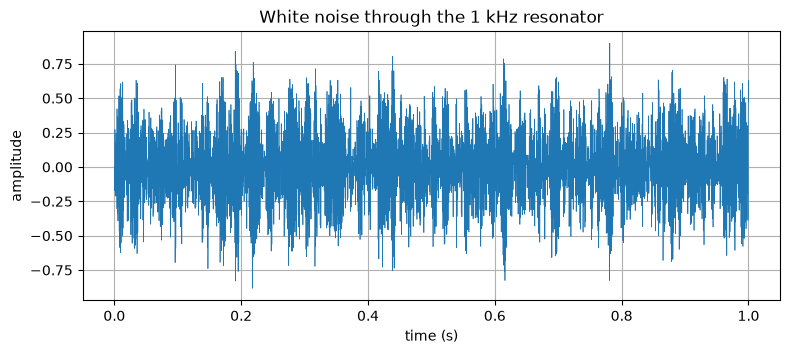

In [6]:
fs = 8000
f0 = 1000
r = 0.97
th0 = 2*np.pi*f0/fs
b_res = np.poly([np.exp(1j*np.pi), np.exp(-1j*np.pi)])          # zeros at z = ±1
a_res = np.poly([r*np.exp(1j*th0), r*np.exp(-1j*th0)])          # pole pair
b_res = np.real(b_res) / np.real(a_res[0])
a_res = np.real(a_res) / np.real(a_res[0])

w, H = signal.freqz(b_res, a_res, worN=4096, fs=fs)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
zplane(b_res, a_res, ax1)
ax1.set_title("Resonator pole–zero diagram")
ax2.plot(w, 20*np.log10(np.abs(H) + 1e-12))
ax2.axvline(f0, color="r", ls="--", lw=0.8)
ax2.set_xlabel("frequency (Hz)"); ax2.set_ylabel("|H| (dB)")
ax2.set_title(f"Resonator response, peak at {f0} Hz")
plt.tight_layout(); plt.show()
print("peak frequency =", round(w[np.argmax(np.abs(H))], 1), "Hz")
print("gain at DC    =", round(abs(signal.freqz(b_res, a_res, worN=[0], fs=fs)[1][0]), 4))
print("gain at fs/2  =", round(abs(signal.freqz(b_res, a_res, worN=[fs/2], fs=fs)[1][0]), 4))

rng = np.random.default_rng(2)
noise = rng.standard_normal(fs)
y = signal.lfilter(b_res, a_res, noise)
y = y / np.max(np.abs(y)) * 0.9
plt.plot(np.arange(fs)/fs, y, lw=0.5)
plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("White noise through the 1 kHz resonator")
plt.show()

from IPython.display import Audio
display(Audio(y, rate=fs))

The response peaks at 1.0 kHz and is −∞ dB at DC and at 4 kHz because of the zeros at $z=\pm1$; the output of white noise is a clean 1 kHz tone with a slow amplitude beat as the resonator rings. This is a **band-pass** filter created purely by pole–zero placement.

## Analysis questions

**1. Explain the effect of $r$ on the bandwidth of the resonance in Task 4.3.**
The −3 dB bandwidth of a pole pair at radius $r$ and angle $\theta$ is approximately $\Delta\omega \approx 2(1-r)$ rad/sample (for $r$ near 1), so the bandwidth shrinks as $r \to 1$; equivalently the Q factor is $\approx 1/[2(1-r)]$. In Hz, $\Delta f = \Delta\omega f_s/(2\pi)$. Raising $r$ from 0.8 to 0.95 narrows the peak by a factor of 4 and lengthens the ring time constant $\tau \approx -1/\ln r$ samples (from 4.5 to 32 samples).

**2. What happens to $h(n)$ when a pole lies exactly on the unit circle?**
The mode $r^n e^{j\theta n}$ becomes $e^{j\theta n}$: a sustained oscillation that never decays, so $\sum|h(n)|$ diverges — the system is **marginally stable** (bounded input can give a bounded but non-decaying output, and at the pole frequency the output grows linearly). It is not BIBO stable, and in finite precision the pole drifts and can become unstable.

**3. Why does placing zeros at $z = \pm1$ make the resonator a band-pass filter?**
$z=1$ corresponds to $\omega = 0$ (DC) and $z=-1$ to $\omega = \pi$ ($f_s/2$). A zero on the unit circle makes $|H| = 0$ at that frequency, so DC and the Nyquist frequency are completely removed while the resonance at 1 kHz is passed — the defining shape of a band-pass response.

**4. Use the stability triangle (handout Example 2.4) to check Task 4.4 (a)–(c).**
For $A(z) = 1 + a_1z^{-1} + a_2z^{-2}$ the triangle conditions are $|a_2| < 1$ and $|a_1| < 1 + a_2$.
(a) $a_1=-1.6$, $a_2=0.89$: $|0.89|<1$ ✔ and $1.6 < 1.89$ ✔ → stable.
(b) $a_1=-2.5$, $a_2=1$: $|a_2| = 1$ fails (on the boundary) and $2.5 < 2$ fails → unstable.
(c) $a_1=0.5$, $a_2=-0.5$: $|a_2|<1$ ✔ but $|0.5| < 1-0.5 = 0.5$ fails (equality) → on the boundary, marginally stable. All three agree with the pole calculation.